In [2]:
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train.shape:", train.shape)
print("tets.shape: ", test.shape)

train.head(10)

train.shape: (699635, 23)
tets.shape:  (299844, 22)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False
5,5,34,584,4,4,4,4,1,4,1,...,4,4,1,0,0.0,Female,disloyal Customer,Business travel,Business,False
6,6,36,1763,5,5,5,5,3,4,4,...,4,3,3,0,0.0,Female,Loyal Customer,Business travel,Business,True
7,7,57,861,1,3,1,3,4,4,4,...,5,4,2,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
8,8,60,581,3,3,3,3,5,4,5,...,4,4,5,0,0.0,Female,Loyal Customer,Business travel,Business,True
9,9,44,588,3,3,2,2,2,3,2,...,4,1,2,0,0.0,Female,disloyal Customer,Business travel,Eco,False


In [7]:
print(train["satisfaction"].value_counts())

satisfaction
False    389296
True     310339
Name: count, dtype: int64


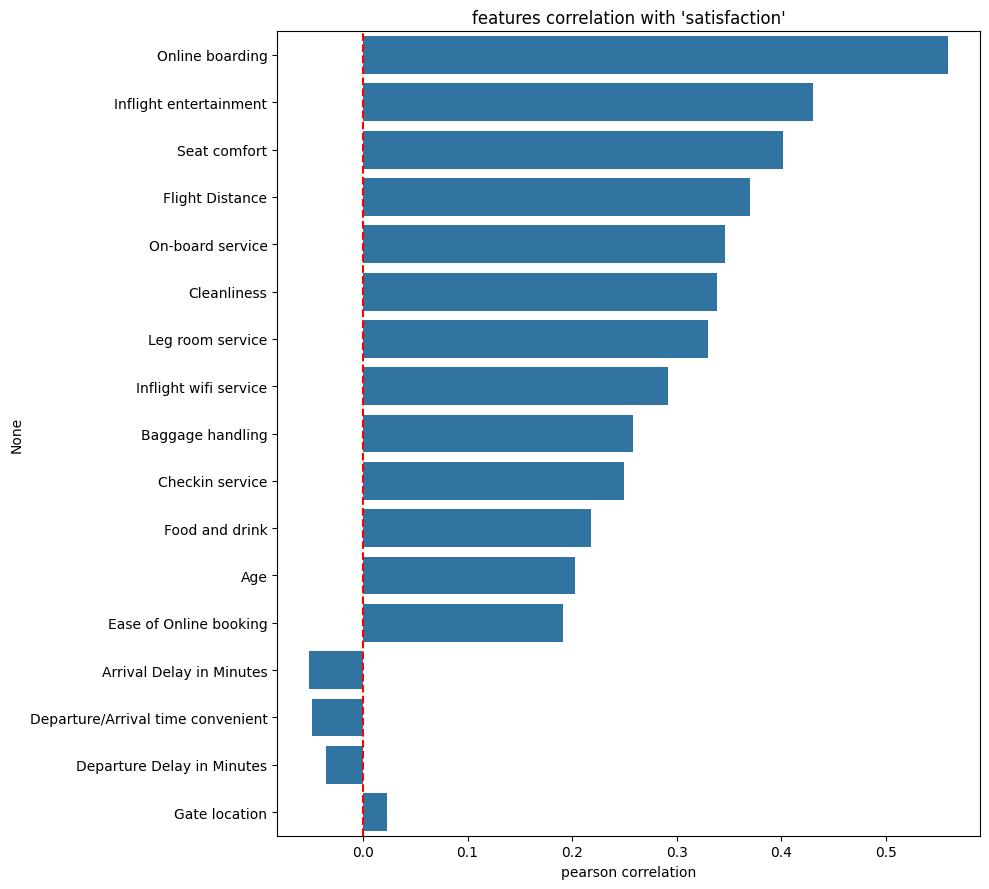

In [11]:
corr = (
    train.drop(columns=["id"])
    .select_dtypes(include = ["number", "bool"])
    .corr()["satisfaction"]
    .drop("satisfaction")
)

corr = corr.reindex(corr.abs().sort_values(ascending = False).index)


plt.figure(figsize=(10,9))
sns.barplot(x=corr.values, y =corr.index)

plt.axvline(0, color="red", linestyle = "--")
plt.title("features correlation with 'satisfaction'")

plt.xlabel("pearson correlation")

plt.tight_layout()
plt.show()


In [12]:
categorical_cols = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for col in categorical_cols:
    print(f"\n{col}")
    print(
        train.groupby(col)["satisfaction"]
        .mean()
        .sort_values(ascending=False)
    )


Gender
Gender
Male      0.449092
Female    0.437994
Name: satisfaction, dtype: float64

Customer Type
Customer Type
Loyal Customer       0.495145
disloyal Customer    0.200946
Name: satisfaction, dtype: float64

Type of Travel
Type of Travel
Business travel    0.584337
Personal Travel    0.097263
Name: satisfaction, dtype: float64

Class
Class
Business    0.725311
Eco Plus    0.242180
Eco         0.167558
Name: satisfaction, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

X = train.drop(columns=["satisfaction", "id"], errors = "ignore")
y=train["satisfaction"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state= 42,
    stratify=y
)


print("training: ", X_train.shape)
print("validation: ", X_val.shape)

training:  (559708, 21)
validation:  (139927, 21)


## first model pipeline

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

#-----------------------------------------------------------------------

numeric_cols = X.select_dtypes(include=["number"]).columns
categorical_cols = X.select_dtypes(include=["object"]).columns


#--numeric & CATGERORIAL preprocessing---------------------------------

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


#----------------------------------------------------------------------

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [16]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)[:, 1]


print("Accuracy: ", accuracy_score(y_val, y_pred))
print("ROC-AUC", roc_auc_score(y_val, y_prob))

Accuracy:  0.8780864307817647
ROC-AUC 0.9204553922590752


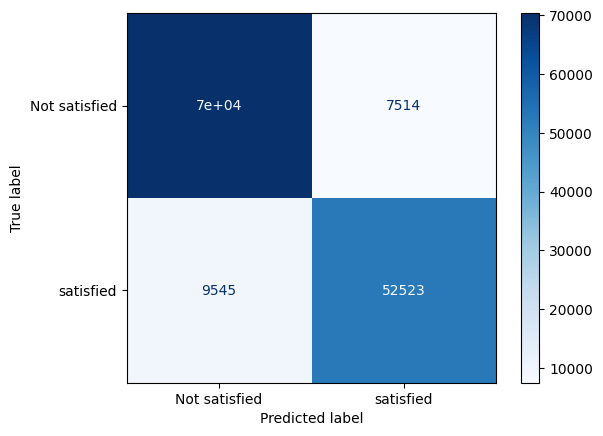

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels = ["Not satisfied", "satisfied"]
).plot(cmap="Blues")

plt.show()

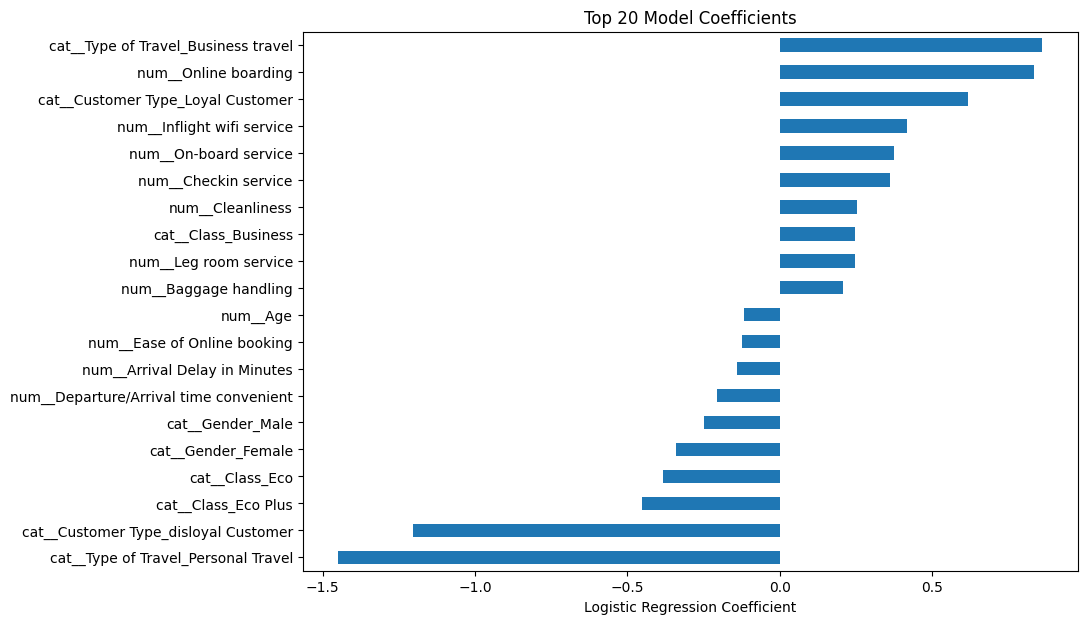

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]

coef = pd.Series(coefficients, index=feature_names)

coef.reindex(coef.abs().sort_values(ascending=False).index).head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.xlabel("Logistic Regression Coefficient")
plt.title("Top 20 Model Coefficients")
plt.show()

#### basic logistic regression was not too bad 

## random forest model

In [21]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators= 100,
        max_depth=20,
        random_state=42,
        n_jobs= -1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_val)
rf_prob = rf_model.predict_proba(X_val)[:, 1]


print("Random forest accuracy: ", accuracy_score(y_val, rf_pred))
print("Random forest ROC-AUC: ", roc_auc_score(y_val, rf_prob))

Random forest accuracy:  0.9241818948451692
Random forest ROC-AUC:  0.9558326408483453


## XGBOOST MODEL

In [28]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators = 400,
        max_depth = 5,
        learning_rate = 0.1,
        subsample = 1.0,
        colsample_bytree = 0.8,
        tree_method = "hist",
        random_state = 42,
        n_jobs = 4,
        eval_metric = "logloss"
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_val)
xgb_prob = xgb_model.predict_proba(X_val)[:, 1]

print("xgboost accuracy:", accuracy_score(y_val, xgb_pred))
print("XGBosst ROC-AUC:", roc_auc_score(y_val, xgb_prob))


xgboost accuracy: 0.9242033345958964
XGBosst ROC-AUC: 0.9571738927267324


## NN model

In [23]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import Pipeline

nn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        batch_size=256,
        max_iter=100,
        early_stopping=True,
        random_state=42
    ))
])

nn_model.fit(X_train, y_train)

nn_pred = nn_model.predict(X_val)
nn_prob = nn_model.predict_proba(X_val)[:, 1]

print("NN Accuracy:", accuracy_score(y_val, nn_pred))
print("NN ROC-AUC:", roc_auc_score(y_val, nn_prob))

NN Accuracy: 0.9236387544934144
NN ROC-AUC: 0.9559051429073253


## random forest Tuning


In [24]:
for name, m in [
    ("Random Forest", rf_model),
    ("Neural Network", nn_model)
]:
    train_auc = roc_auc_score(
        y_train, m.predict_proba(X_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, m.predict_proba(X_val)[:, 1]
    )

    print(f"{name}")
    print(f"Train AUC: {train_auc:.4f}")
    print(f"Val AUC:   {val_auc:.4f}")
    print(f"Gap:       {train_auc - val_auc:.4f}")
    print()

Random Forest
Train AUC: 0.9842
Val AUC:   0.9558
Gap:       0.0283

Neural Network
Train AUC: 0.9595
Val AUC:   0.9559
Gap:       0.0036



In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

configs = [
    {"max_depth": 10, "min_samples_leaf": 5},
    {"max_depth": 15, "min_samples_leaf": 3},
    {"max_depth": 20, "min_samples_leaf": 2},
]

for config in configs:
    rf = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
            **config
        ))
    ])

    rf.fit(X_train, y_train)

    train_auc = roc_auc_score(
        y_train, rf.predict_proba(X_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, rf.predict_proba(X_val)[:, 1]
    )

    print(config)
    print(f"Train AUC: {train_auc:.4f}")
    print(f"Val AUC: {val_auc:.4f}")
    print(f"Gap: {train_auc - val_auc:.4f}\n")

{'max_depth': 10, 'min_samples_leaf': 5}
Train AUC: 0.9564
Val AUC: 0.9535
Gap: 0.0029

{'max_depth': 15, 'min_samples_leaf': 3}
Train AUC: 0.9672
Val AUC: 0.9557
Gap: 0.0115

{'max_depth': 20, 'min_samples_leaf': 2}
Train AUC: 0.9810
Val AUC: 0.9560
Gap: 0.0250



## NN tuning


In [26]:
configs = [
    (128, 64),
    (128, 64, 32)
]

for layers in configs:
    nn = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=layers,
            activation="relu",
            solver="adam",
            alpha=0.001,
            learning_rate_init=0.001,
            batch_size=256,
            max_iter=100,
            early_stopping=True,
            random_state=42
        ))
    ])

    nn.fit(X_train, y_train)

    train_auc = roc_auc_score(
        y_train, nn.predict_proba(X_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, nn.predict_proba(X_val)[:, 1]
    )

    print(f"Layers: {layers}")
    print(f"Train AUC: {train_auc:.4f}")
    print(f"Val AUC: {val_auc:.4f}")
    print(f"Gap: {train_auc - val_auc:.4f}\n")

Layers: (128, 64)
Train AUC: 0.9615
Val AUC: 0.9555
Gap: 0.0060

Layers: (128, 64, 32)
Train AUC: 0.9596
Val AUC: 0.9564
Gap: 0.0033



## xgboost tuning

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        tree_method="hist",
        random_state=42,
        n_jobs=4,
        eval_metric="logloss"
    ))
])

params = {
    "classifier__n_estimators": [200, 400, 600],
    "classifier__max_depth": [3, 5, 7],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0],
}

search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=params,
    n_iter=10,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=2
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)
print("CV AUC:", search.best_score_)

best_xgb = search.best_estimator_

print(
    "Validation AUC:",
    roc_auc_score(
        y_val,
        best_xgb.predict_proba(X_val)[:, 1]
    )
)

Best Parameters: {'classifier__subsample': 1.0, 'classifier__n_estimators': 400, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__colsample_bytree': 0.8}
CV AUC: 0.9582591844505672
Validation AUC: 0.9571738927267324


### catboost model


In [12]:
X_cb = X_train.copy()
X_cb_val = X_val.copy()

cat_cols = X_cb.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in cat_cols:
    print("Processing:", col)
    X_cb[col] = X_cb[col].fillna("__MISSING__").astype(str)
    X_cb_val[col] = X_cb_val[col].fillna("__MISSING__").astype(str)

print("Ready")

Processing: Gender
Processing: Customer Type
Processing: Type of Travel
Processing: Class
Ready


In [17]:
print("Type:", type(X_train))
print("Shape:", X_train.shape)
print("Duplicate columns:",
      X_train.columns[X_train.columns.duplicated()].tolist())

X_cb = X_train.copy()
print("Copy OK")

Type: <class 'pandas.core.frame.DataFrame'>
Shape: (559708, 21)
Duplicate columns: []
Copy OK


In [25]:
from catboost import CatBoostClassifier


X_fit, X_stop, y_fit, y_stop = train_test_split(
    X_cb,y_train,
    test_size= 0.15,
    random_state = 42,
    stratify= y_train
)


params = dict(
    loss_function="Logloss",
    eval_metric = "AUC",
    depth = 6,
    l2_leaf_reg = 15,
    learning_rate = 0.05,
    random_seed = 42,
    allow_writing_files = False

)


probe = CatBoostClassifier(iterations=3000, **params)

probe.fit(
    X_fit, y_fit,
    cat_features = cat_cols,
    eval_set = (X_stop, y_stop),
    early_stopping_rounds = 150,
    verbose = 200
)

cb_model = CatBoostClassifier(
    iterations = probe.best_iteration_ +1,
    **params
)

cb_model.fit(
    X_cb, y_train, 
    cat_features = cat_cols,
    verbose = 200
)

cb_prob = cb_model.predict_proba(X_cb_val)[:, 1]

print("trees: ", cb_model.tree_count_)
print("Catboost validation AUC: ", roc_auc_score(y_val, cb_prob))

0:	test: 0.9346408	best: 0.9346408 (0)	total: 231ms	remaining: 11m 34s
200:	test: 0.9567785	best: 0.9567785 (200)	total: 37.7s	remaining: 8m 44s
400:	test: 0.9575476	best: 0.9575476 (400)	total: 1m 13s	remaining: 7m 58s
600:	test: 0.9579275	best: 0.9579280 (599)	total: 1m 53s	remaining: 7m 34s
800:	test: 0.9581710	best: 0.9581710 (800)	total: 2m 37s	remaining: 7m 13s
1000:	test: 0.9582840	best: 0.9582854 (997)	total: 3m 17s	remaining: 6m 34s
1200:	test: 0.9583476	best: 0.9583489 (1198)	total: 3m 56s	remaining: 5m 54s
1400:	test: 0.9584369	best: 0.9584369 (1400)	total: 4m 34s	remaining: 5m 13s
1600:	test: 0.9585003	best: 0.9585003 (1600)	total: 5m 17s	remaining: 4m 37s
1800:	test: 0.9585572	best: 0.9585572 (1800)	total: 6m 2s	remaining: 4m 1s
2000:	test: 0.9585893	best: 0.9585893 (2000)	total: 6m 52s	remaining: 3m 25s
2200:	test: 0.9586409	best: 0.9586433 (2190)	total: 7m 40s	remaining: 2m 47s
2400:	test: 0.9586778	best: 0.9586813 (2396)	total: 8m 28s	remaining: 2m 6s
2600:	test: 0.9587

In [26]:
train_auc = roc_auc_score(
    y_train, cb_model.predict_proba(X_cb)[:, 1]
)
val_auc = roc_auc_score(y_val, cb_prob)

print(f"Train AUC: {train_auc:.7f}")
print(f"Val AUC:   {val_auc:.7f}")
print(f"Gap:       {train_auc - val_auc:.7f}")
print("Trees:", cb_model.tree_count_)

Train AUC: 0.9636180
Val AUC:   0.9577149
Gap:       0.0059030
Trees: 2997


In [21]:
print("Probe best scores:", probe.best_score_)

cb_prob = cb_model.predict_proba(X_cb_val)[:, 1]
print("Final validation AUC:", roc_auc_score(y_val, cb_prob))

Probe best scores: {'learn': {'Logloss': 0.21674725604575465}, 'validation': {'Logloss': 0.226986135665147, 'AUC': 0.9588103678122922}}
Final validation AUC: 0.9577561581136557


In [22]:
cb_depth6 = cb_model
cb_depth6_prob = cb_prob.copy()

In [27]:
from sklearn.metrics import roc_auc_score

p1 = cb_depth6_prob                       # depth=6, L2=5
p2 = cb_model.predict_proba(X_cb_val)[:, 1]  # مدل فعلی
p_mix = (p1 + p2) / 2

auc1 = roc_auc_score(y_val, p1)
auc2 = roc_auc_score(y_val, p2)
auc_mix = roc_auc_score(y_val, p_mix)

print(f"CatBoost 1: {auc1:.7f}")
print(f"CatBoost 2: {auc2:.7f}")
print(f"Blend 50/50: {auc_mix:.7f}")
print(f"Gain over best: {auc_mix - max(auc1, auc2):+.7f}")

CatBoost 1: 0.9577562
CatBoost 2: 0.9577149
Blend 50/50: 0.9577804
Gain over best: +0.0000243


In [29]:
p_mix = (cb_depth6_prob + xgb_prob) / 2
auc_mix = roc_auc_score(y_val, p_mix)

print(f"CatBoost + XGBoost AUC: {auc_mix:.7f}")
print(f"Gain vs previous blend: {auc_mix - 0.9577804:+.7f}")

CatBoost + XGBoost AUC: 0.9576746
Gain vs previous blend: -0.0001058
